# Anomaly / Suspicious-Traffic Detector

Unsupervised Isolation Forest trained **only on BENIGN traffic**. It scores how unusual a flow is compared to normal traffic,
so it can flag suspicious behaviour even for attack types it has never seen. Labels are used only for evaluation.

- Same 24 features as the attack classifier (`dst_port` excluded), duplicates removed.
- Features are log-like transformed with `arcsinh` (handles the `-1` window-size values and heavy-tailed rates/durations).
- Risk levels come from BENIGN validation percentiles: **Low** < 95th, **Medium** 95th to 99th, **High** >= 99th.
- `N_JOBS = 2` keeps CPU free for other jobs running in parallel.

In [1]:
import json
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Locate the repository root so the notebook runs from any checkout location.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "requirements.txt").exists() and (p / "src").is_dir()
)

DATA_PATH = PROJECT_ROOT / "data" / "cleaned_network_data" / "cleaned_network_data.csv"
MODEL_DIR = PROJECT_ROOT / "ml" / "models"
RANDOM_STATE = 42
N_JOBS = 2
MEDIUM_PCT = 95
HIGH_PCT = 99

## 1. Load data, select features, remove duplicates

In [2]:
df = pd.read_csv(DATA_PATH)
FEATURES = [c for c in df.columns if c not in ("label", "dst_port")]

before = len(df)
df = df.drop_duplicates(subset=FEATURES).reset_index(drop=True)
df["is_attack"] = (df["label"] != "BENIGN").astype(int)

print("Features used:", len(FEATURES))
print(f"Rows: {before:,} -> {len(df):,} (removed {before - len(df):,} duplicate feature vectors)")
print(df["is_attack"].value_counts().rename({0: "BENIGN", 1: "attack"}))

Features used: 24
Rows: 97,548 -> 87,222 (removed 10,326 duplicate feature vectors)
is_attack
BENIGN    49834
attack    37388
Name: count, dtype: int64


## 2. Split

- BENIGN: 60% train / 20% validation (sets thresholds) / 20% test
- All attack rows go to the test set only (the model never sees attacks)

In [3]:
benign = df[df["is_attack"] == 0]
attacks = df[df["is_attack"] == 1]

benign_train, benign_rest = train_test_split(benign, test_size=0.4, random_state=RANDOM_STATE)
benign_val, benign_test = train_test_split(benign_rest, test_size=0.5, random_state=RANDOM_STATE)

test_df = pd.concat([benign_test, attacks]).reset_index(drop=True)

print("BENIGN train:", len(benign_train))
print("BENIGN val  :", len(benign_val))
print("Test        :", len(test_df), f"({len(benign_test):,} BENIGN + {len(attacks):,} attacks)")

BENIGN train: 29900
BENIGN val  : 9967
Test        : 47355 (9,967 BENIGN + 37,388 attacks)


## 3. Model pipeline

`arcsinh` behaves like a log for large values but also works for zero and negative values, and it is a plain NumPy
function so the saved pipeline loads anywhere. No scaler is needed: Isolation Forest splits each feature independently,
so linear scaling does not change its result.

In [4]:
def build_pipeline(log_transform=True):
    steps = []
    if log_transform:
        steps.append(("arcsinh", FunctionTransformer(np.arcsinh, feature_names_out="one-to-one")))
    steps.append(("iforest", IsolationForest(
        n_estimators=200,
        contamination="auto",
        random_state=RANDOM_STATE,
        n_jobs=N_JOBS,
    )))
    return Pipeline(steps)


def anomaly_score(pipeline, X):
    # Higher = more anomalous.
    return -pipeline.score_samples(X)


pipeline = build_pipeline().fit(benign_train[FEATURES])
print(pipeline)

Pipeline(steps=[('arcsinh',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<ufunc 'arcsinh'>)),
                ('iforest',
                 IsolationForest(n_estimators=200, n_jobs=2, random_state=42))])


## 4. Does the log transform help? (raw vs arcsinh, ROC-AUC on test)

In [5]:
raw_pipeline = build_pipeline(log_transform=False).fit(benign_train[FEATURES])

y_test = test_df["is_attack"]
test_scores = anomaly_score(pipeline, test_df[FEATURES])
raw_scores = anomaly_score(raw_pipeline, test_df[FEATURES])

print(f"ROC-AUC raw features    : {roc_auc_score(y_test, raw_scores):.4f}")
print(f"ROC-AUC arcsinh features: {roc_auc_score(y_test, test_scores):.4f}")

ROC-AUC raw features    : 0.8063
ROC-AUC arcsinh features: 0.8552


## 5. Risk thresholds from BENIGN validation scores

In [6]:
val_scores = anomaly_score(pipeline, benign_val[FEATURES])

THRESHOLDS = {
    "medium": float(np.percentile(val_scores, MEDIUM_PCT)),
    "high": float(np.percentile(val_scores, HIGH_PCT)),
}

# Reference curve used to turn a raw score into "more unusual than X% of normal traffic".
PCT_LEVELS = np.linspace(0, 100, 1001)
PCT_SCORES = np.percentile(val_scores, PCT_LEVELS)


def risk_level(scores):
    return np.select(
        [scores >= THRESHOLDS["high"], scores >= THRESHOLDS["medium"]],
        ["High", "Medium"],
        default="Low",
    )


def benign_percentile(scores):
    return np.interp(scores, PCT_SCORES, PCT_LEVELS)


print("Thresholds:", {k: round(v, 4) for k, v in THRESHOLDS.items()})

Thresholds: {'medium': 0.5777, 'high': 0.6152}


## 6. Evaluate on the test set

In [7]:
test_df["anomaly_score"] = test_scores
test_df["risk_level"] = risk_level(test_scores)

benign_mask = test_df["is_attack"] == 0
metrics = {
    "roc_auc": roc_auc_score(y_test, test_scores),
    "average_precision": average_precision_score(y_test, test_scores),
    "benign_false_alarm_rate_medium_or_high": float((test_df.loc[benign_mask, "risk_level"] != "Low").mean()),
    "benign_false_alarm_rate_high": float((test_df.loc[benign_mask, "risk_level"] == "High").mean()),
    "attack_detection_rate_medium_or_high": float((test_df.loc[~benign_mask, "risk_level"] != "Low").mean()),
    "attack_detection_rate_high": float((test_df.loc[~benign_mask, "risk_level"] == "High").mean()),
}

for name, value in metrics.items():
    print(f"{name:40}: {value:.4f}")

roc_auc                                 : 0.8552
average_precision                       : 0.9338
benign_false_alarm_rate_medium_or_high  : 0.0506
benign_false_alarm_rate_high            : 0.0098
attack_detection_rate_medium_or_high    : 0.2564
attack_detection_rate_high              : 0.0392


In [8]:
# Share of each traffic type that lands in each risk level.
per_class = (
    pd.crosstab(test_df["label"], test_df["risk_level"], normalize="index")
    .reindex(columns=["Low", "Medium", "High"], fill_value=0)
    .assign(flagged=lambda t: t["Medium"] + t["High"], rows=test_df["label"].value_counts())
    .sort_values("flagged", ascending=False)
)

print(per_class.round(3).to_string())

risk_level                    Low  Medium   High  flagged  rows
label                                                          
Heartbleed                  0.000   0.000  1.000    1.000    11
Infiltration                0.194   0.111  0.694    0.806    36
DoS Hulk                    0.286   0.712  0.002    0.714  7819
DoS Slowhttptest            0.361   0.099  0.539    0.639  2584
PortScan                    0.401   0.574  0.026    0.599   392
DoS slowloris               0.778   0.222  0.000    0.222  2632
DDoS                        0.818   0.182  0.000    0.182  7843
BENIGN                      0.949   0.041  0.010    0.051  9967
Bot                         0.970   0.023  0.007    0.030  1424
SSH-Patator                 0.995   0.005  0.000    0.005  3149
Web Attack - XSS            0.998   0.002  0.000    0.002   651
FTP-Patator                 0.999   0.001  0.000    0.001  4258
DoS GoldenEye               1.000   0.000  0.000    0.000  5246
Web Attack - Brute Force    1.000   0.00

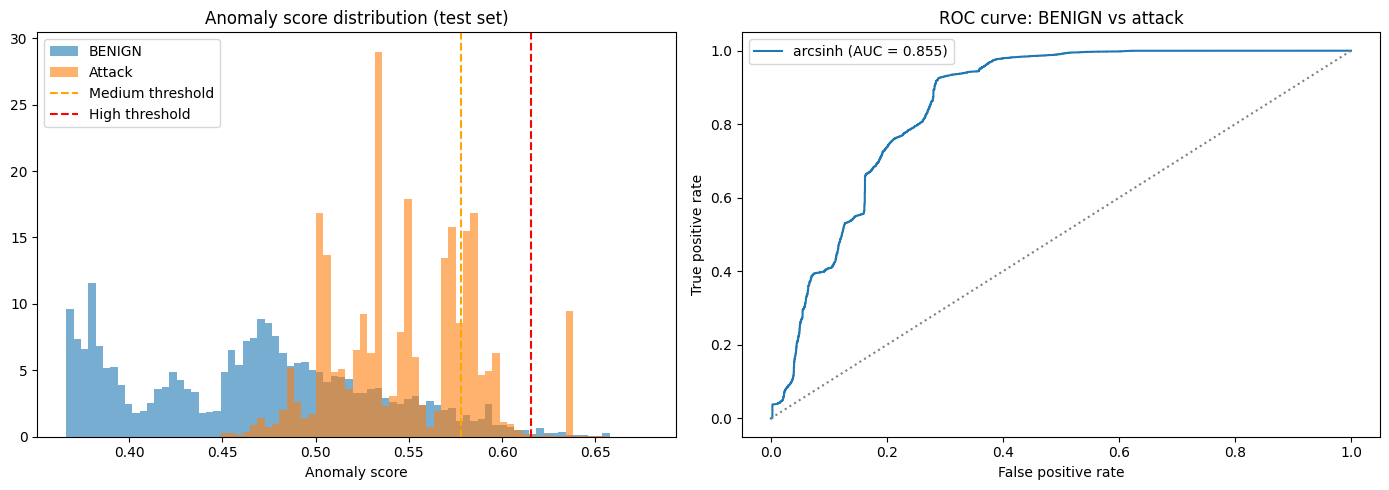

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bins = np.linspace(test_scores.min(), test_scores.max(), 80)
axes[0].hist(test_scores[benign_mask], bins=bins, alpha=0.6, density=True, label="BENIGN")
axes[0].hist(test_scores[~benign_mask], bins=bins, alpha=0.6, density=True, label="Attack")
axes[0].axvline(THRESHOLDS["medium"], color="orange", linestyle="--", label="Medium threshold")
axes[0].axvline(THRESHOLDS["high"], color="red", linestyle="--", label="High threshold")
axes[0].set_xlabel("Anomaly score")
axes[0].set_title("Anomaly score distribution (test set)")
axes[0].legend()

fpr, tpr, _ = roc_curve(y_test, test_scores)
axes[1].plot(fpr, tpr, label=f"arcsinh (AUC = {metrics['roc_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", linestyle=":")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve: BENIGN vs attack")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Save model and metadata

In [10]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "anomaly_detector.pkl"
meta_path = MODEL_DIR / "anomaly_detector_meta.json"

joblib.dump(pipeline, model_path)

meta = {
    "model": "Pipeline(arcsinh -> IsolationForest)",
    "trained_at": datetime.now().isoformat(timespec="seconds"),
    "sklearn_version": sklearn.__version__,
    "data_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "trained_on": "BENIGN only",
    "excluded_columns": ["dst_port"],
    "features": FEATURES,
    "score_definition": "anomaly_score = -pipeline.score_samples(X); higher = more anomalous",
    "risk_levels": {
        "Low": f"score < {MEDIUM_PCT}th percentile of BENIGN validation",
        "Medium": f"{MEDIUM_PCT}th to {HIGH_PCT}th percentile",
        "High": f">= {HIGH_PCT}th percentile",
    },
    "thresholds": {k: round(v, 6) for k, v in THRESHOLDS.items()},
    "benign_percentile_reference": {
        "levels": PCT_LEVELS.round(1).tolist(),
        "scores": PCT_SCORES.round(6).tolist(),
    },
    "n_benign_train": len(benign_train),
    "n_benign_val": len(benign_val),
    "n_test": len(test_df),
    "test_metrics": {k: round(v, 4) for k, v in metrics.items()},
}
meta_path.write_text(json.dumps(meta, indent=2))

print("Saved:", model_path)
print("Saved:", meta_path)

Saved: D:\Cybersecurity-assistant\ml\models\anomaly_detector.pkl
Saved: D:\Cybersecurity-assistant\ml\models\anomaly_detector_meta.json


## 8. Load-and-score check

In [11]:
loaded = joblib.load(model_path)
loaded_meta = json.loads(meta_path.read_text())

# One test row per traffic type.
samples = test_df.groupby("label").head(1)
scores = anomaly_score(loaded, samples[loaded_meta["features"]])

check = pd.DataFrame({
    "label": samples["label"].values,
    "anomaly_score": scores.round(4),
    "benign_percentile": benign_percentile(scores).round(1),
    "risk_level": risk_level(scores),
})

print(check.to_string(index=False))

                     label  anomaly_score  benign_percentile risk_level
                    BENIGN         0.3805               12.0        Low
                  DoS Hulk         0.5850               96.3     Medium
                  PortScan         0.5699               93.5        Low
                      DDoS         0.5253               80.6        Low
             DoS GoldenEye         0.5688               93.2        Low
             DoS slowloris         0.5747               94.6        Low
          Web Attack - XSS         0.5467               87.3        Low
               FTP-Patator         0.5337               83.6        Low
               SSH-Patator         0.5040               71.8        Low
  Web Attack - Brute Force         0.5460               87.0        Low
                       Bot         0.4692               49.4        Low
          DoS Slowhttptest         0.5532               89.1        Low
                Heartbleed         0.6566               99.9    

## 9. Test with custom data

Edit the values in `custom_flow` and run the two cells below.
No retraining needed: after a kernel restart, run only the **first cell** (imports and paths) and then these cells.

Tip: to start from a real flow instead, use `custom_flow = test_df[FEATURES].iloc[0].to_dict()` (requires the earlier cells to have run).

In [12]:
# Edit any value below. The example is a BENIGN-looking web flow from CIC-IDS2017.
custom_flow = {
    "flow_duration": 452460.0,
    "total_fwd_packets": 8.0,
    "total_bwd_packets": 11.0,
    "total_len_fwd": 1763.0,
    "total_len_bwd": 12834.0,
    "flow_packets_s": 41.992662,
    "fwd_packets_s": 17.681121,
    "bwd_packets_s": 24.311541,
    "fwd_packet_length_mean": 220.375,
    "bwd_packet_length_mean": 1166.727273,
    "min_packet_length": 0.0,
    "max_packet_length": 1514.0,
    "packet_length_mean": 628.5,
    "packet_length_std": 500.0,
    "syn_flag_count": 0.0,
    "ack_flag_count": 0.0,
    "rst_flag_count": 0.0,
    "psh_flag_count": 1.0,
    "fin_flag_count": 0.0,
    "down_up_ratio": 1.0,
    "init_win_bytes_forward": 8192.0,
    "init_win_bytes_backward": 1095.0,
    "active_mean": 0.0,
    "idle_mean": 0.0,
}

In [13]:
saved_model = joblib.load(MODEL_DIR / "anomaly_detector.pkl")
saved_meta = json.loads((MODEL_DIR / "anomaly_detector_meta.json").read_text())


def score_flow(flow):
    features = saved_meta["features"]
    missing = [f for f in features if f not in flow]
    if missing:
        raise ValueError(f"Missing features: {missing}")
    extra = [f for f in flow if f not in features]
    if extra:
        print("Ignoring unknown fields:", extra)

    row = pd.DataFrame([flow])[features]
    score = float(-saved_model.score_samples(row)[0])

    ref = saved_meta["benign_percentile_reference"]
    percentile = float(np.interp(score, ref["scores"], ref["levels"]))

    th = saved_meta["thresholds"]
    level = "High" if score >= th["high"] else "Medium" if score >= th["medium"] else "Low"

    print(f"Anomaly score : {score:.4f}")
    print(f"More unusual than {percentile:.1f}% of normal (BENIGN) traffic")
    print(f"Risk level    : {level}")
    return {"anomaly_score": score, "benign_percentile": percentile, "risk_level": level}


score_flow(custom_flow);

Anomaly score : 0.4933
More unusual than 65.7% of normal (BENIGN) traffic
Risk level    : Low
